# A2：KDE 递归训练完整复现

**实验：** Blobs / Circles / Moons / Swiss Roll × Replace / Accumulate-Subsample / Accumulate × 带宽 0.1 / 0.5 / 1.0 × n=10/32/100/316/1000 × seeds 0–99 × 100 轮。  
**评价：** 固定 500 个真实测试样本上的平均负对数似然（NLL）。  
**输出：** 原始逐轮 CSV、聚合 CSV、三张 4×3 论文风格图（PNG + PDF）。  


## Cell 1 — 安装依赖

In [3]:
%pip install -q numpy pandas scipy scikit-learn "seaborn>=0.12" matplotlib tqdm


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Cell 2 — 导入库与正式参数

In [5]:
import os
import csv
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn import datasets
from sklearn.neighbors import KernelDensity

DATASETS = ["blobs", "circles", "moons", "swiss_roll"]
SETTINGS = ["Replace", "Accumulate-Subsample", "Accumulate"]
BANDWIDTHS = [0.1, 0.5, 1.0]
SAMPLE_SIZES = [10, 32, 100, 316, 1000]
SEEDS = list(range(100))
NUM_ITERATIONS = 100
TEST_SIZE = 500
KERNEL = "gaussian"

ROOT = Path("/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results")
RAW_DIR = ROOT / "raw_by_config"
FIG_DIR = ROOT / "figures"
RAW_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("总轨迹数:", len(DATASETS) * len(SETTINGS) * len(BANDWIDTHS) * len(SAMPLE_SIZES) * len(SEEDS))
print("每条轨迹轮数:", NUM_ITERATIONS)
print("输出目录:", ROOT.resolve())

总轨迹数: 18000
每条轨迹轮数: 100
输出目录: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results


## Cell 3 — 真实数据生成

In [7]:
def create_dataset_for_kde(dataset_name: str, n_samples: int) -> np.ndarray:
    if dataset_name == "blobs":
        X, _ = datasets.make_blobs(n_samples=n_samples, n_features=2)
    elif dataset_name == "circles":
        X, _ = datasets.make_circles(n_samples=n_samples, noise=0.05)
    elif dataset_name == "moons":
        X, _ = datasets.make_moons(n_samples=n_samples, noise=0.05)
    elif dataset_name == "swiss_roll":
        X, _ = datasets.make_swiss_roll(n_samples=n_samples, noise=0.05)
    else:
        raise ValueError(f"Unknown dataset: {dataset_name}")
    return np.asarray(X, dtype=np.float64)

## Cell 4 — 三种策略的单条递归轨迹

In [9]:
COLUMNS = ["Dataset", "Setting", "Bandwidth", "Num Samples per Iteration",
           "Seed", "Model-Fitting Iteration", "Eval NLL on Real Data"]


def run_kde_experiment(dataset_name, setting, bandwidth, n, seed):
    assert setting in SETTINGS
    np.random.seed(int(seed))
    init_data_train = create_dataset_for_kde(dataset_name, n)
    init_data_test = create_dataset_for_kde(dataset_name, TEST_SIZE)
    all_data_train = init_data_train.copy()

    kde = KernelDensity(kernel=KERNEL, bandwidth=float(bandwidth))
    records = []
    for iteration_idx in range(1, NUM_ITERATIONS + 1):
        if setting in ("Accumulate", "Replace"):
            kde.fit(all_data_train)
        else:  # Accumulate-Subsample：从累计池中无放回抽取 n 个样本
            subsample_idx = np.random.choice(
                np.arange(all_data_train.shape[0]), size=n, replace=False
            )
            kde.fit(all_data_train[subsample_idx])

        
        mean_nll = -np.mean(kde.score_samples(init_data_test))
        records.append((dataset_name, setting, float(bandwidth), int(n),
                        int(seed), iteration_idx, float(mean_nll)))

        
        new_data = kde.sample(n_samples=n)
        if setting == "Replace":
            all_data_train = new_data
        else:
            all_data_train = np.concatenate((all_data_train, new_data), axis=0)

    return pd.DataFrame.from_records(records, columns=COLUMNS)

## Cell 5 — 正式运行全部 18,000 条轨迹，逐条保存并支持续跑

In [11]:
def config_csv_path(dataset_name, setting, bandwidth, n):
    setting_slug = setting.lower().replace("-", "_")
    return RAW_DIR / f"{dataset_name}__{setting_slug}__h{bandwidth:g}__n{n}.csv"


def completed_seeds(path):
    if not path.exists() or path.stat().st_size == 0:
        return set()
    # 仅把恰好包含 100 个不同轮次的 seed 视为已完成；若发生意外中断，
    # 对不完整的 seed 重新计算，并在追加前清理其旧记录。
    existing = pd.read_csv(path, usecols=["Seed", "Model-Fitting Iteration"])
    counts = existing.groupby("Seed")["Model-Fitting Iteration"].nunique()
    return set(counts[counts == NUM_ITERATIONS].index.astype(int))


def append_completed_run(path, run_df):
    header = not path.exists() or path.stat().st_size == 0
    run_df.to_csv(path, mode="a", index=False, header=header)


start_time = time.time()
all_configs = [(d, s, h, n) for d in DATASETS for s in SETTINGS
               for h in BANDWIDTHS for n in SAMPLE_SIZES]

for dataset_name, setting, bandwidth, n in tqdm(all_configs, desc="参数组合"):
    path = config_csv_path(dataset_name, setting, bandwidth, n)
    done = completed_seeds(path)

    # 清理异常中断留下的不完整轨迹或重复 seed，确保断点续跑结果唯一。
    if path.exists() and path.stat().st_size > 0:
        old = pd.read_csv(path)
        valid = old[old["Seed"].isin(done)].drop_duplicates(
            subset=["Seed", "Model-Fitting Iteration"], keep="first"
        )
        if len(valid) != len(old):
            valid.to_csv(path, index=False)

    for seed in SEEDS:
        if seed in done:
            continue
        run_df = run_kde_experiment(dataset_name, setting, bandwidth, n, seed)
        append_completed_run(path, run_df)

    print(f"完成: {dataset_name:10s} | {setting:20s} | h={bandwidth:g} | n={n:4d}")

print(f"全部实验完成，用时 {(time.time()-start_time)/3600:.2f} 小时")

参数组合:   0%|          | 0/180 [00:00<?, ?it/s]

完成: blobs      | Replace              | h=0.1 | n=  10
完成: blobs      | Replace              | h=0.1 | n=  32
完成: blobs      | Replace              | h=0.1 | n= 100
完成: blobs      | Replace              | h=0.1 | n= 316
完成: blobs      | Replace              | h=0.1 | n=1000
完成: blobs      | Replace              | h=0.5 | n=  10
完成: blobs      | Replace              | h=0.5 | n=  32
完成: blobs      | Replace              | h=0.5 | n= 100
完成: blobs      | Replace              | h=0.5 | n= 316
完成: blobs      | Replace              | h=0.5 | n=1000
完成: blobs      | Replace              | h=1 | n=  10
完成: blobs      | Replace              | h=1 | n=  32
完成: blobs      | Replace              | h=1 | n= 100
完成: blobs      | Replace              | h=1 | n= 316
完成: blobs      | Replace              | h=1 | n=1000
完成: blobs      | Accumulate-Subsample | h=0.1 | n=  10
完成: blobs      | Accumulate-Subsample | h=0.1 | n=  32
完成: blobs      | Accumulate-Subsample | h=0.1 | n= 100
完成: blobs      | Acc

## Cell 6 — 汇总原始数据，检查完整性并保存总 CSV

In [17]:
paths = sorted(RAW_DIR.glob("*.csv"))
expected_configs = len(DATASETS) * len(SETTINGS) * len(BANDWIDTHS) * len(SAMPLE_SIZES)
assert len(paths) == expected_configs, f"应有 {expected_configs} 个参数组合文件，实际 {len(paths)} 个"

raw_results = pd.concat((pd.read_csv(p) for p in tqdm(paths, desc="合并 CSV")),
                        ignore_index=True)
key_cols = ["Dataset", "Setting", "Bandwidth", "Num Samples per Iteration",
            "Seed", "Model-Fitting Iteration"]
assert not raw_results.duplicated(key_cols).any(), "发现重复轨迹记录"
expected_rows = expected_configs * len(SEEDS) * NUM_ITERATIONS
assert len(raw_results) == expected_rows, f"应有 {expected_rows:,} 行，实际 {len(raw_results):,} 行"
assert np.isfinite(raw_results["Eval NLL on Real Data"]).all(), "NLL 存在 NaN/Inf，需检查"

raw_path = ROOT / "kde_all_raw_results.csv"
raw_results.to_csv(raw_path, index=False)


summary_cols = [
    "Dataset",
    "Setting",
    "Bandwidth",
    "Num Samples per Iteration",
    "Model-Fitting Iteration"
]

summary_results = (
    raw_results
    .groupby(summary_cols)["Eval NLL on Real Data"]
    .agg(
        NLL_mean="mean",
        NLL_std="std",
        Num_Seeds="count"
    )
    .reset_index()
)

# 保存汇总结果
summary_path = ROOT / "kde_summary_results.csv"
summary_results.to_csv(summary_path, index=False)

print("汇总结果保存至：", summary_path)
print("汇总数据形状：", summary_results.shape)
print("列名：", summary_results.columns.tolist())

display(summary_results.head())

合并 CSV:   0%|          | 0/180 [00:00<?, ?it/s]

汇总结果保存至： /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/kde_summary_results.csv
汇总数据形状： (18000, 8)
列名： ['Dataset', 'Setting', 'Bandwidth', 'Num Samples per Iteration', 'Model-Fitting Iteration', 'NLL_mean', 'NLL_std', 'Num_Seeds']


,Dataset,Setting,Bandwidth,Num Samples per Iteration,Model-Fitting Iteration,NLL_mean,NLL_std,Num_Seeds
0,blobs,Accumulate,0.1,10,1,2205.013212,1686.615445,100
1,blobs,Accumulate,0.1,10,2,2181.601267,1677.214134,100
2,blobs,Accumulate,0.1,10,3,2169.259850,1672.840882,100
3,blobs,Accumulate,0.1,10,4,2158.316262,1666.981796,100
4,blobs,Accumulate,0.1,10,5,2150.578816,1663.969026,100


## Cell 7 — 绘制三个带宽的 4×3 综合图

保存: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.1.png
保存: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.1.pdf


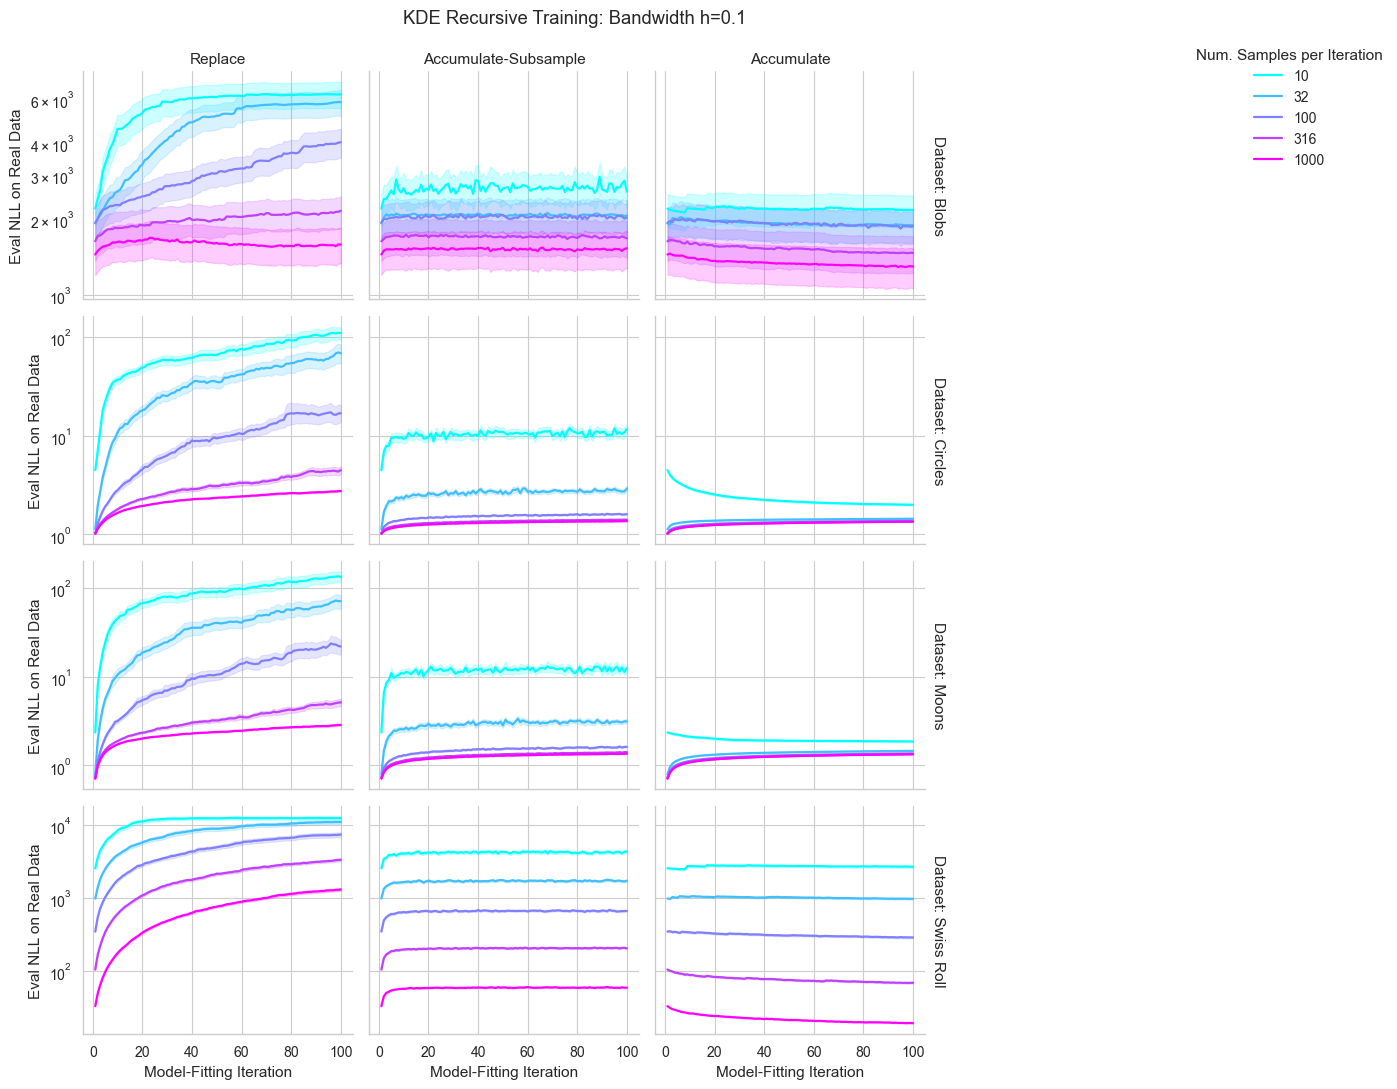

保存: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.5.png
保存: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.5.pdf


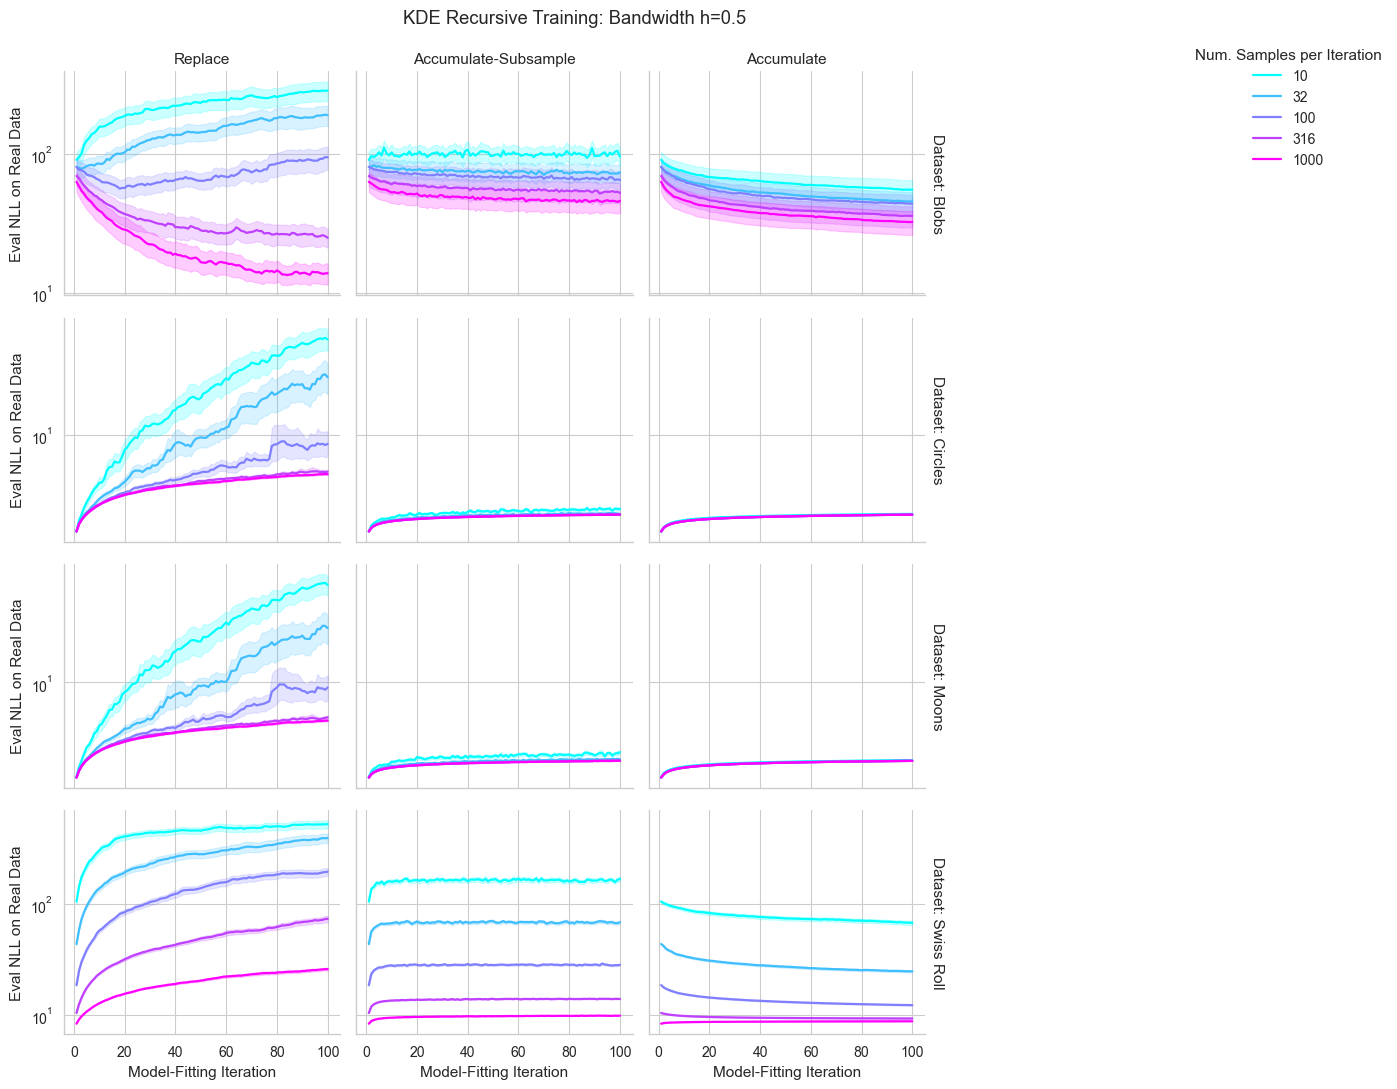

保存: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_1.png
保存: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_1.pdf


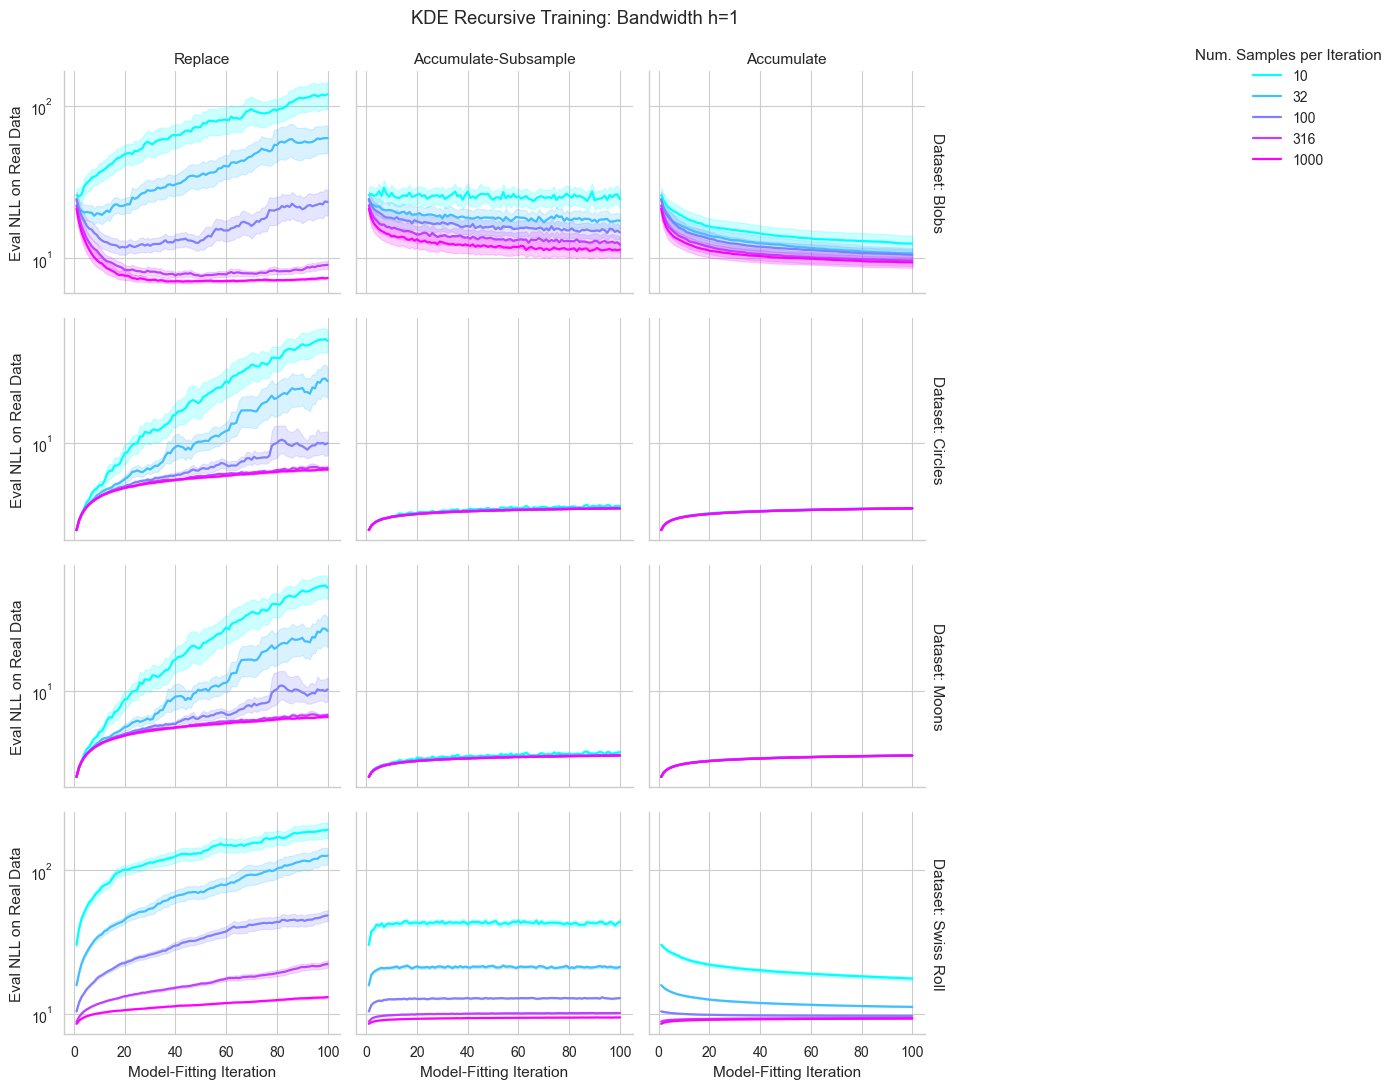

In [19]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

DATASET_NAMES = {"blobs": "Blobs", "circles": "Circles",
                 "moons": "Moons", "swiss_roll": "Swiss Roll"}
PLOT_SETTINGS = ["Replace", "Accumulate-Subsample", "Accumulate"]

plot_data = raw_results.copy()
plot_data["Dataset"] = plot_data["Dataset"].map(DATASET_NAMES)
plot_data = plot_data.rename(columns={"Num Samples per Iteration": "Num. Samples per Iteration"})

for bandwidth in BANDWIDTHS:
    subset = plot_data.loc[plot_data["Bandwidth"] == bandwidth].copy()
    plt.close("all")
    g = sns.relplot(
        data=subset,
        kind="line",
        x="Model-Fitting Iteration",
        y="Eval NLL on Real Data",
        row="Dataset",
        row_order=["Blobs", "Circles", "Moons", "Swiss Roll"],
        col="Setting",
        col_order=PLOT_SETTINGS,
        hue="Num. Samples per Iteration",
        hue_order=SAMPLE_SIZES,
        hue_norm=matplotlib.colors.LogNorm(),
        palette="cool",
        estimator="mean",
        errorbar=("ci", 95),  # 显式固定 seaborn 默认均值 95% bootstrap CI
        n_boot=1000,
        seed=0,
        facet_kws={"sharex": True, "sharey": "row", "margin_titles": True},
        legend="full",
        height=2.65,
        aspect=1.25,
        linewidth=1.6,
    )
    # NLL 可能为负值（连续密度的负对数似然可以小于 0）。
    # 论文使用对数纵轴；若数据包含非正值，改用线性轴以免静默丢点。
    if (subset["Eval NLL on Real Data"] > 0).all():
        g.set(yscale="log")
    else:
        print(f"注意 h={bandwidth:g} 包含非正 NLL，使用线性纵轴，避免丢失数据。")
    g.set_titles(col_template="{col_name}", row_template="Dataset: {row_name}")
    g.set_axis_labels("Model-Fitting Iteration", "Eval NLL on Real Data")
    sns.move_legend(g, "upper left", bbox_to_anchor=(1.01, 1))
    g.figure.suptitle(f"KDE Recursive Training: Bandwidth h={bandwidth:g}", y=1.025)

    out_name = f"kde_bandwidth_{bandwidth:g}"
    for ext in ("png", "pdf"):
        out_path = FIG_DIR / f"{out_name}.{ext}"
        g.figure.savefig(out_path, bbox_inches="tight", dpi=300)
        print("保存:", out_path)
    plt.show()
    plt.close(g.figure)

## Cell 8 — 检查最终文件

In [21]:
for p in sorted(FIG_DIR.glob("*")):
    print(p, f"({p.stat().st_size/1024:.1f} KB)")
print("总原始记录:", len(raw_results))
print("独立轨迹:", raw_results[key_cols[:-1]].drop_duplicates().shape[0])
print("所有输出:", ROOT.resolve())

/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.1.pdf (155.3 KB)
/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.1.png (990.0 KB)
/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.5.pdf (152.1 KB)
/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_0.5.png (910.2 KB)
/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_1.pdf (150.5 KB)
/Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results/figures/kde_bandwidth_1.png (888.3 KB)
总原始记录: 1800000
独立轨迹: 18000
所有输出: /Users/liandan/博士生/高维数据的统计推断/A2_KDE/kde_A2_results
